In [1]:
import os
import h5py
import requests
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive,userdata
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
os.chdir("/content/drive/MyDrive/TNGdata")

In [4]:
baseUrl = 'http://www.tng-project.org/api/'
headers = {"api-key":userdata.get("TNG_API_KEY")}

In [5]:
def get(path, params=None):
    # make HTTP GET request to path
    r = requests.get(path, params=params, headers=headers)

    # raise exception if response code is not HTTP SUCCESS (200)
    r.raise_for_status()

    if r.headers['content-type'] == 'application/json':
        return r.json() # parse json responses automatically

    if 'content-disposition' in r.headers:
        filename = r.headers['content-disposition'].split("filename=")[1]
        with open(filename, 'wb') as f:
            f.write(r.content)
        return filename # return the filename string

    return r

In [7]:
r = get(baseUrl)

In [8]:
data = np.load("subhalo_data_with_bhmasses.npz")
data = data["data"]

sfrs = data[:,0,0]
bhmdots = data[:,0,1]
mass_stars = data[:,0,2]
mass_bhmdots = data[:,0,3]
mass_log_msun = data[:,0,4]

normalized_sfrs = sfrs / mass_stars
normalized_bhmdots = bhmdots / mass_bhmdots

/tmp/ipykernel_3145/1313167293.py:11: RuntimeWarning: invalid value encountered in divide
  normalized_bhmdots = bhmdots / mass_bhmdots


<>:7: SyntaxWarning: invalid escape sequence '\d'
<>:7: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_3145/2645594199.py:7: SyntaxWarning: invalid escape sequence '\d'
  plt.boxplot([clean_norm_sfrs, clean_norm_bhmdots], tick_labels=['SFR/m_stars', '$\dot{M}_{BH}$/m_BH'])


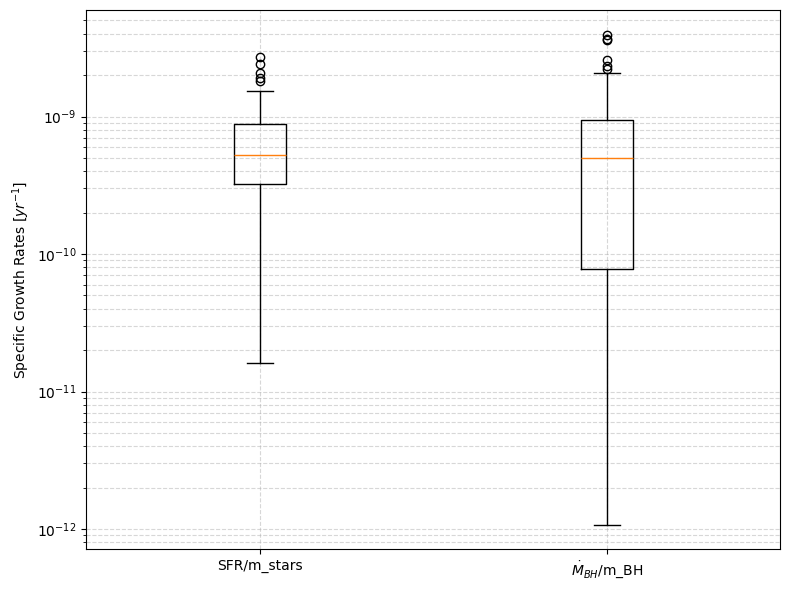

In [11]:
valid_mask = (sfrs >= 0) & (bhmdots >= 0) & (mass_stars > 0) & (mass_bhmdots > 0)

clean_norm_sfrs = normalized_sfrs[valid_mask]
clean_norm_bhmdots = normalized_bhmdots[valid_mask]

plt.figure(figsize=(8, 6))
plt.boxplot([clean_norm_sfrs, clean_norm_bhmdots], tick_labels=['SFR/m_stars', '$\dot{M}_{BH}$/m_BH'])
plt.yscale('log')
plt.ylabel('Specific Growth Rates [$yr^{-1}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("SFR&Bhmdotbox.png", dpi=300)
plt.show()

<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:8: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_3145/2268317145.py:8: SyntaxWarning: invalid escape sequence '\d'
  '$\dot{M}_{BH}$/m_BH': {


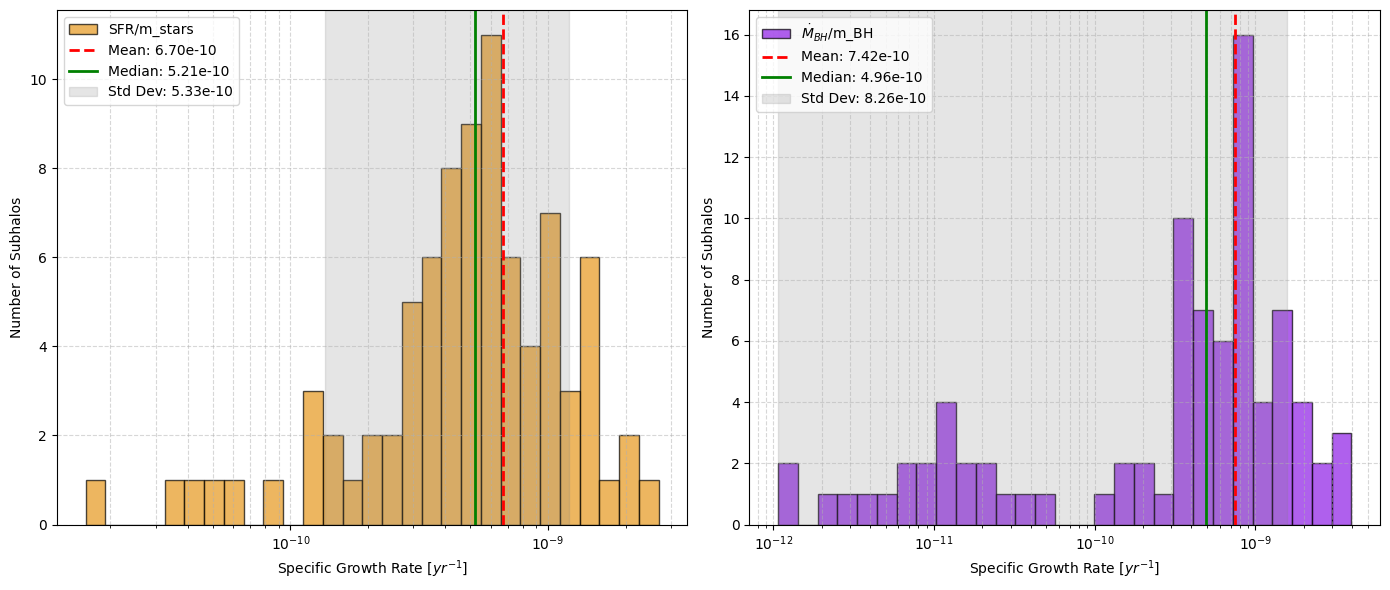

In [12]:
stats = {
    'SFR/m_stars': {
        'data': clean_norm_sfrs,
        'mean': np.mean(clean_norm_sfrs),
        'median': np.median(clean_norm_sfrs),
        'std': np.std(clean_norm_sfrs)
    },
    '$\dot{M}_{BH}$/m_BH': {
        'data': clean_norm_bhmdots,
        'mean': np.mean(clean_norm_bhmdots),
        'median': np.median(clean_norm_bhmdots),
        'std': np.std(clean_norm_bhmdots)
    }
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#e6981c', '#8e1ce6']

for ax, color, (label, s_data) in zip(axes, colors, stats.items()):
    bins = np.logspace(np.log10(s_data['data'].min()), np.log10(s_data['data'].max()), 30)

    ax.hist(s_data['data'], bins=bins, color=color, alpha=0.7, edgecolor='black', label=label)

    ax.axvline(s_data['mean'], color='red', linestyle='--', linewidth=2, label=f"Mean: {s_data['mean']:.2e}")
    ax.axvline(s_data['median'], color='green', linestyle='-', linewidth=2, label=f"Median: {s_data['median']:.2e}")

    ax.axvspan(max(s_data['data'].min(), s_data['mean'] - s_data['std']),
               s_data['mean'] + s_data['std'],
               color='gray', alpha=0.2, label=f"Std Dev: {s_data['std']:.2e}")

    ax.set_xscale('log')
    ax.set_xlabel('Specific Growth Rate [$yr^{-1}$]')
    ax.set_ylabel('Number of Subhalos')

    ax.legend()
    ax.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("SFR_BHMdot_histograms.png", dpi=300)
plt.show()

<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:11: SyntaxWarning: invalid escape sequence '\d'
<>:8: SyntaxWarning: invalid escape sequence '\d'
<>:11: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_3145/1864454134.py:8: SyntaxWarning: invalid escape sequence '\d'
  plt.hist(clean_norm_bhmdots, bins=bins, color='#8e1ce6', alpha=0.5, edgecolor='black', label='$\dot{M}_{BH}$/m_BH')
/tmp/ipykernel_3145/1864454134.py:11: SyntaxWarning: invalid escape sequence '\d'
  plt.axvline(np.mean(clean_norm_bhmdots), color='#8e1ce6', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_norm_bhmdots):.2e}")


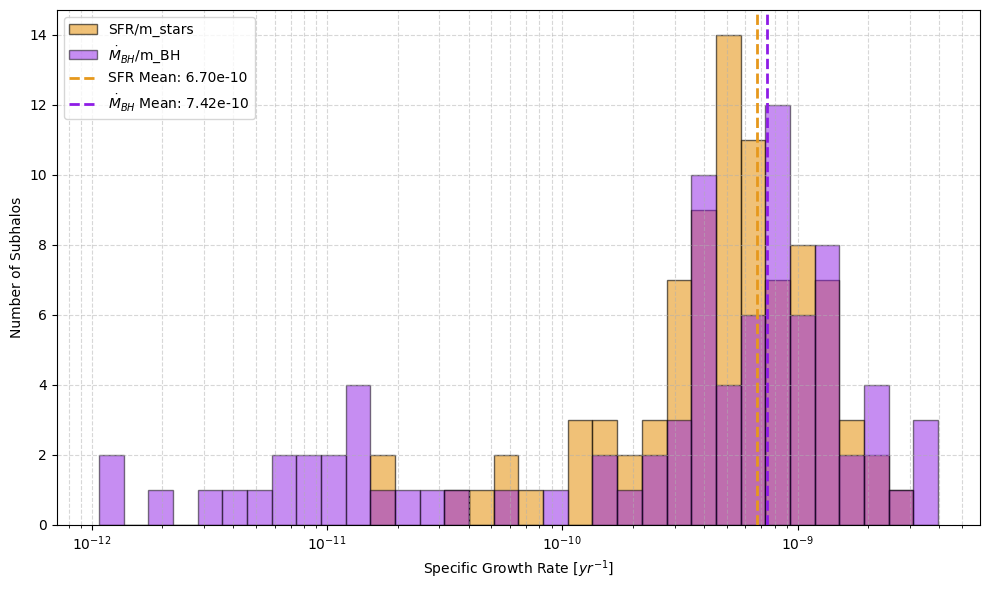

In [13]:
min_val = min(clean_norm_sfrs.min(), clean_norm_bhmdots.min())
max_val = max(clean_norm_sfrs.max(), clean_norm_bhmdots.max())
bins = np.logspace(np.log10(min_val), np.log10(max_val), 35)

plt.figure(figsize=(10, 6))

plt.hist(clean_norm_sfrs, bins=bins, color='#e6981c', alpha=0.6, edgecolor='black', label='SFR/m_stars')
plt.hist(clean_norm_bhmdots, bins=bins, color='#8e1ce6', alpha=0.5, edgecolor='black', label='$\dot{M}_{BH}$/m_BH')

plt.axvline(np.mean(clean_norm_sfrs), color='#e6981c', linestyle='--', linewidth=2, label=f"SFR Mean: {np.mean(clean_norm_sfrs):.2e}")
plt.axvline(np.mean(clean_norm_bhmdots), color='#8e1ce6', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_norm_bhmdots):.2e}")

plt.xscale('log')
plt.xlabel('Specific Growth Rate [$yr^{-1}$]')
plt.ylabel('Number of Subhalos')
plt.legend(loc='upper left')
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("SFR_BHMdot_overlapping_histogram.png", dpi=300)
plt.show()

### Part 1: Visualizations of Actual (Unnormalized) SFR and $\dot{M}_{\text{BH}}$

- **Star Formation Rate (SFR)** in units of $[\text{M}_{\odot} \, \text{yr}^{-1}]$
- **Black Hole Accretion Rate ($\dot{M}_{\text{BH}}$)** in units of $[\text{M}_{\odot} \, \text{yr}^{-1}]$

<>:5: SyntaxWarning: invalid escape sequence '\d'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\d'
<>:7: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3145/3665824039.py:5: SyntaxWarning: invalid escape sequence '\d'
  plt.boxplot([clean_sfrs, clean_bhmdots], tick_labels=['SFR', '$\dot{M}_{BH}$'])
/tmp/ipykernel_3145/3665824039.py:7: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('Actual Rates [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')


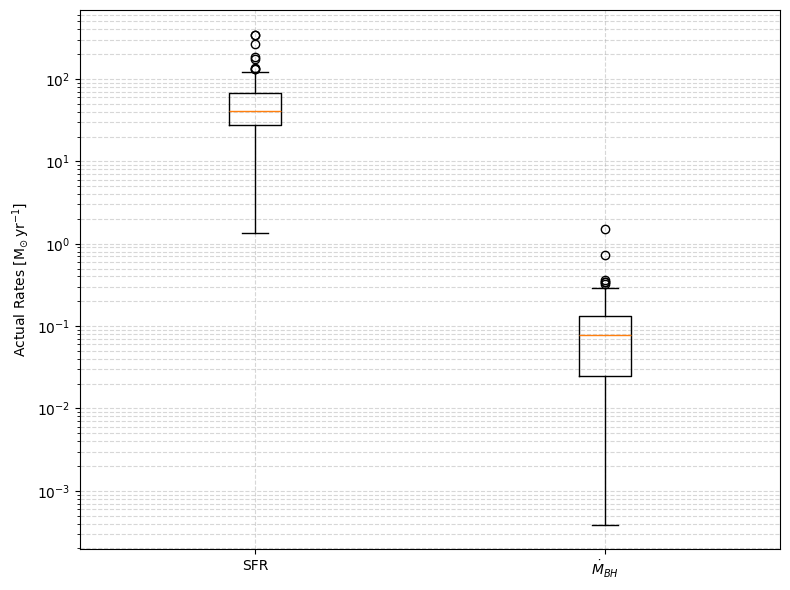

In [14]:
clean_sfrs = sfrs[valid_mask]
clean_bhmdots = bhmdots[valid_mask]

plt.figure(figsize=(8, 6))
plt.boxplot([clean_sfrs, clean_bhmdots], tick_labels=['SFR', '$\dot{M}_{BH}$'])
plt.yscale('log')
plt.ylabel('Actual Rates [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("actual_rates_boxplot.png", dpi=300)
plt.show()

<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3145/3178477444.py:30: SyntaxWarning: invalid escape sequence '\m'
  ax.set_xlabel('Actual Rate [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')


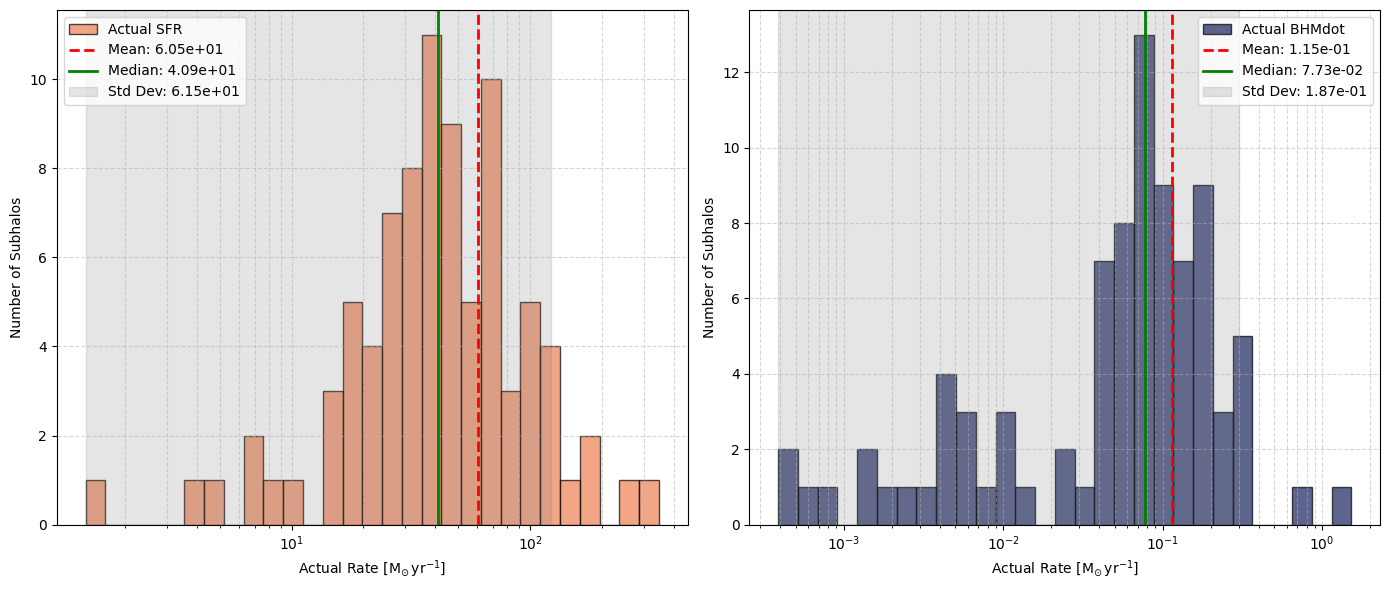

In [15]:
actual_stats = {
    'Actual SFR': {
        'data': clean_sfrs,
        'mean': np.mean(clean_sfrs),
        'median': np.median(clean_sfrs),
        'std': np.std(clean_sfrs)
    },
    'Actual BHMdot': {
        'data': clean_bhmdots,
        'mean': np.mean(clean_bhmdots),
        'median': np.median(clean_bhmdots),
        'std': np.std(clean_bhmdots)
    }
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#ed8153', '#18235e']

for ax, color, (label, s_data) in zip(axes, colors, actual_stats.items()):
    bins = np.logspace(np.log10(s_data['data'].min()), np.log10(s_data['data'].max()), 30)

    ax.hist(s_data['data'], bins=bins, color=color, alpha=0.7, edgecolor='black', label=label)
    ax.axvline(s_data['mean'], color='red', linestyle='--', linewidth=2, label=f"Mean: {s_data['mean']:.2e}")
    ax.axvline(s_data['median'], color='green', linestyle='-', linewidth=2, label=f"Median: {s_data['median']:.2e}")
    ax.axvspan(max(s_data['data'].min(), s_data['mean'] - s_data['std']),
               s_data['mean'] + s_data['std'],
               color='gray', alpha=0.2, label=f"Std Dev: {s_data['std']:.2e}")

    ax.set_xscale('log')
    ax.set_xlabel('Actual Rate [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')
    ax.set_ylabel('Number of Subhalos')
    ax.legend()
    ax.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("actual_rates_side_by_side.png", dpi=300)
plt.show()

<>:7: SyntaxWarning: invalid escape sequence '\d'
<>:10: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:7: SyntaxWarning: invalid escape sequence '\d'
<>:10: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3145/4290175656.py:7: SyntaxWarning: invalid escape sequence '\d'
  plt.hist(clean_bhmdots, bins=bins, color='#18235e', alpha=0.5, edgecolor='black', label='Actual $\dot{M}_{BH}$')
/tmp/ipykernel_3145/4290175656.py:10: SyntaxWarning: invalid escape sequence '\d'
  plt.axvline(np.mean(clean_bhmdots), color='#18235e', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_bhmdots):.2e}")
/tmp/ipykernel_3145/4290175656.py:13: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Actual Rate [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')


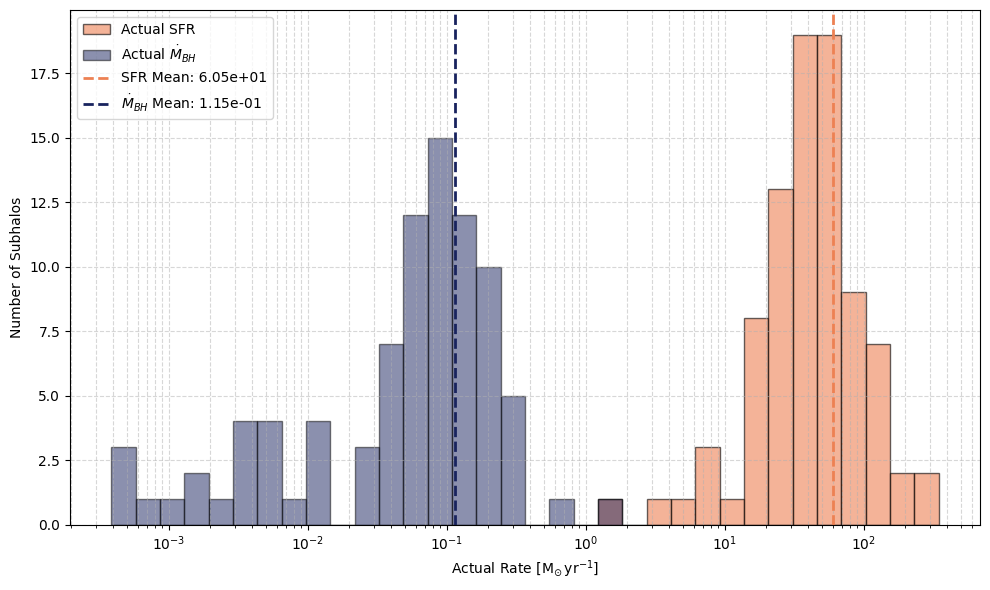

In [16]:
min_val = min(clean_sfrs.min(), clean_bhmdots.min())
max_val = max(clean_sfrs.max(), clean_bhmdots.max())
bins = np.logspace(np.log10(min_val), np.log10(max_val), 35)

plt.figure(figsize=(10, 6))
plt.hist(clean_sfrs, bins=bins, color='#ed8153', alpha=0.6, edgecolor='black', label='Actual SFR')
plt.hist(clean_bhmdots, bins=bins, color='#18235e', alpha=0.5, edgecolor='black', label='Actual $\dot{M}_{BH}$')

plt.axvline(np.mean(clean_sfrs), color='#ed8153', linestyle='--', linewidth=2, label=f"SFR Mean: {np.mean(clean_sfrs):.2e}")
plt.axvline(np.mean(clean_bhmdots), color='#18235e', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_bhmdots):.2e}")

plt.xscale('log')
plt.xlabel('Actual Rate [$\mathrm{M}_{\odot} \, \mathrm{yr}^{-1}$]')
plt.ylabel('Number of Subhalos')
plt.legend(loc='upper left')
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("actual_rates_overlapping.png", dpi=300)
plt.show()

### Part 2: Analysis of Stellar Mass ($M_{\star}$) and Black Hole Mass ($M_{\text{BH}}$)


In [17]:
clean_mstar = mass_stars[valid_mask]
clean_mbh = mass_bhmdots[valid_mask]

print("=== Stellar Mass (M_star) Statistics ===")
print(f"Mean:   {np.mean(clean_mstar):.2e} M_sun")
print(f"Median: {np.median(clean_mstar):.2e} M_sun")
print(f"Min:    {np.min(clean_mstar):.2e} M_sun")
print(f"Max:    {np.max(clean_mstar):.2e} M_sun\n")

print("=== Black Hole Mass (M_BH) Statistics ===")
print(f"Mean:   {np.mean(clean_mbh):.2e} M_sun")
print(f"Median: {np.median(clean_mbh):.2e} M_sun")
print(f"Min:    {np.min(clean_mbh):.2e} M_sun")
print(f"Max:    {np.max(clean_mbh):.2e} M_sun")

=== Stellar Mass (M_star) Statistics ===
Mean:   1.15e+11 M_sun
Median: 7.39e+10 M_sun
Min:    4.48e+10 M_sun
Max:    6.00e+11 M_sun

=== Black Hole Mass (M_BH) Statistics ===
Mean:   2.45e+08 M_sun
Median: 1.85e+08 M_sun
Min:    3.50e+07 M_sun
Max:    1.17e+09 M_sun


<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:16: SyntaxWarning: invalid escape sequence '\m'
<>:15: SyntaxWarning: invalid escape sequence '\m'
<>:16: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3145/1917909132.py:15: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('m_star [$\mathrm{M}_{\odot}$]')
/tmp/ipykernel_3145/1917909132.py:16: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('m_BH [$\mathrm{M}_{\odot}$]')


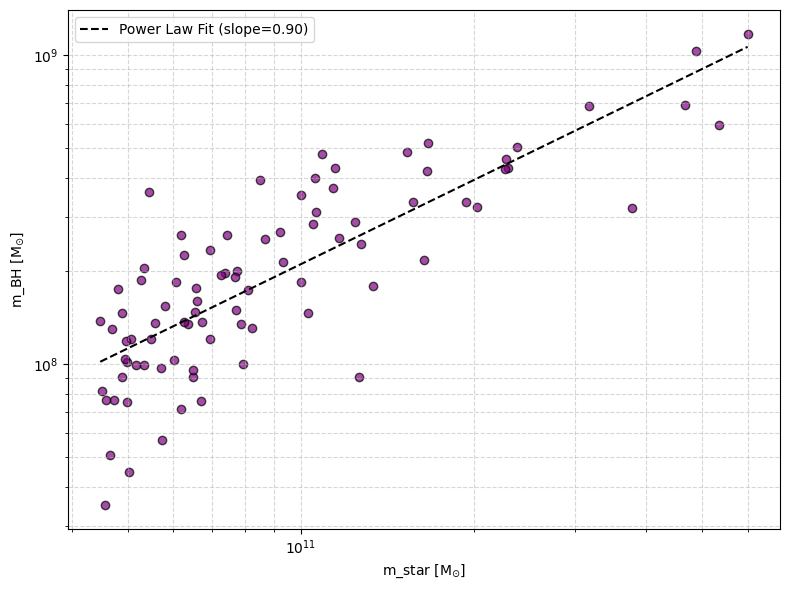

In [18]:
plt.figure(figsize=(8, 6))
plt.scatter(clean_mstar, clean_mbh, color='purple', alpha=0.7, edgecolors='k')

log_mstar = np.log10(clean_mstar)
log_mbh = np.log10(clean_mbh)
slope, intercept = np.polyfit(log_mstar, log_mbh, 1)

mstar_fit = np.logspace(np.log10(clean_mstar.min()), np.log10(clean_mstar.max()), 100)
bh_fit = 10**intercept * mstar_fit**slope

plt.plot(mstar_fit, bh_fit, color='black', linestyle='--', label=f'Power Law Fit (slope={slope:.2f})')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('m_star [$\mathrm{M}_{\odot}$]')
plt.ylabel('m_BH [$\mathrm{M}_{\odot}$]')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("mass_scaling_relation.png", dpi=300)
plt.show()

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3145/4227700653.py:2: SyntaxWarning: invalid escape sequence '\s'
  plt.boxplot([clean_mstar, clean_mbh], tick_labels=['m_star ($M_{\star}$)', 'm_BH ($M_{\mathrm{BH}}$)'])
/tmp/ipykernel_3145/4227700653.py:2: SyntaxWarning: invalid escape sequence '\m'
  plt.boxplot([clean_mstar, clean_mbh], tick_labels=['m_star ($M_{\star}$)', 'm_BH ($M_{\mathrm{BH}}$)'])
/tmp/ipykernel_3145/4227700653.py:4: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('Mass range [$\mathrm{M}_{\odot}$]')


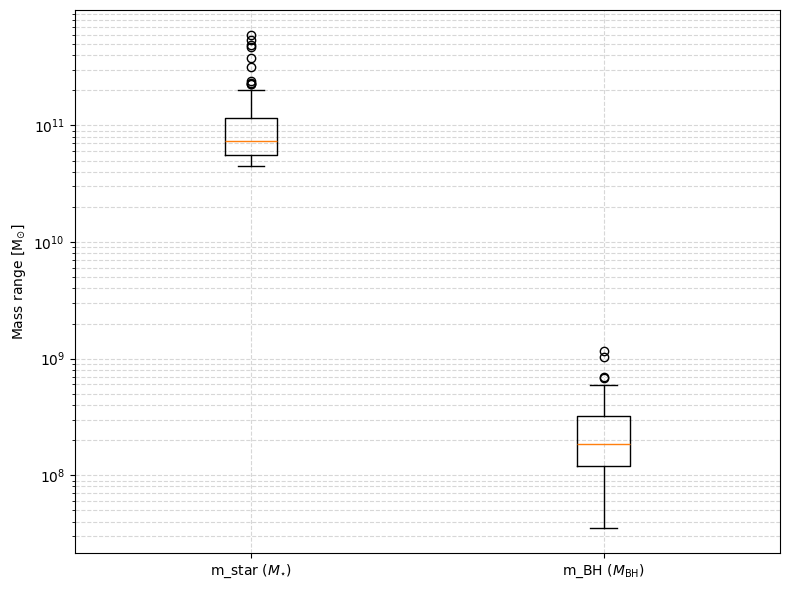

In [19]:
plt.figure(figsize=(8, 6))
plt.boxplot([clean_mstar, clean_mbh], tick_labels=['m_star ($M_{\star}$)', 'm_BH ($M_{\mathrm{BH}}$)'])
plt.yscale('log')
plt.ylabel('Mass range [$\mathrm{M}_{\odot}$]')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("masses_boxplot.png", dpi=300)
plt.show()

<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3145/2846071177.py:9: SyntaxWarning: invalid escape sequence '\m'
  axes[0].set_xlabel('m_star [$\mathrm{M}_{\odot}$]')
/tmp/ipykernel_3145/2846071177.py:20: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_xlabel('m_BH [$\mathrm{M}_{\odot}$]')


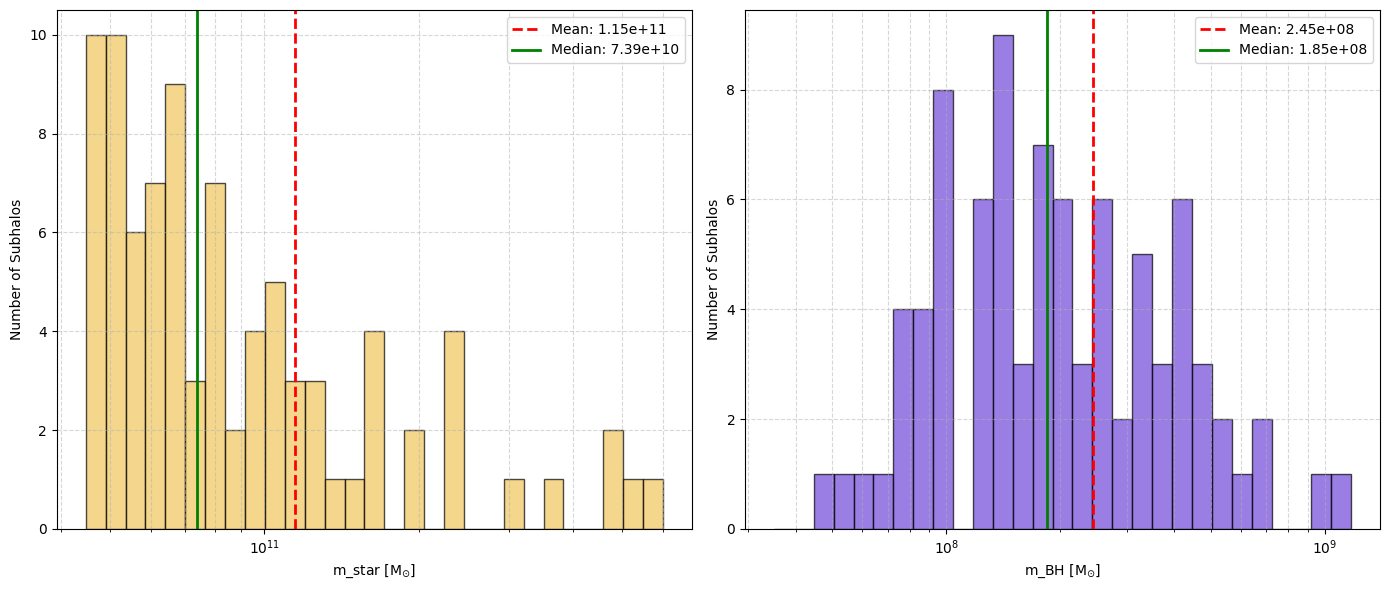

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Stellar Mass Histogram
bins_star = np.logspace(np.log10(clean_mstar.min()), np.log10(clean_mstar.max()), 30)
axes[0].hist(clean_mstar, bins=bins_star, color='#f0c65d', alpha=0.7, edgecolor='black')
axes[0].axvline(np.mean(clean_mstar), color='red', linestyle='--', linewidth=2, label=f"Mean: {np.mean(clean_mstar):.2e}")
axes[0].axvline(np.median(clean_mstar), color='green', linestyle='-', linewidth=2, label=f"Median: {np.median(clean_mstar):.2e}")
axes[0].set_xscale('log')
axes[0].set_xlabel('m_star [$\mathrm{M}_{\odot}$]')
axes[0].set_ylabel('Number of Subhalos')
axes[0].legend()
axes[0].grid(True, which="both", ls="--", alpha=0.5)

# Black Hole Mass Histogram
bins_bh = np.logspace(np.log10(clean_mbh.min()), np.log10(clean_mbh.max()), 30)
axes[1].hist(clean_mbh, bins=bins_bh, color='#7148d9', alpha=0.7, edgecolor='black')
axes[1].axvline(np.mean(clean_mbh), color='red', linestyle='--', linewidth=2, label=f"Mean: {np.mean(clean_mbh):.2e}")
axes[1].axvline(np.median(clean_mbh), color='green', linestyle='-', linewidth=2, label=f"Median: {np.median(clean_mbh):.2e}")
axes[1].set_xscale('log')
axes[1].set_xlabel('m_BH [$\mathrm{M}_{\odot}$]')
axes[1].set_ylabel('Number of Subhalos')
axes[1].legend()
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig("masses_side_by_side.png", dpi=300)
plt.show()

<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:10: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\d'
<>:10: SyntaxWarning: invalid escape sequence '\d'
<>:13: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3145/2503929229.py:9: SyntaxWarning: invalid escape sequence '\d'
  plt.axvline(np.mean(clean_mstar), color='#f0c65d', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_mstar):.2e}")
/tmp/ipykernel_3145/2503929229.py:10: SyntaxWarning: invalid escape sequence '\d'
  plt.axvline(np.mean(clean_mbh), color='#7148d9', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_mbh):.2e}")
/tmp/ipykernel_3145/2503929229.py:13: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Mass [$\mathrm{M}_{\odot}$]')


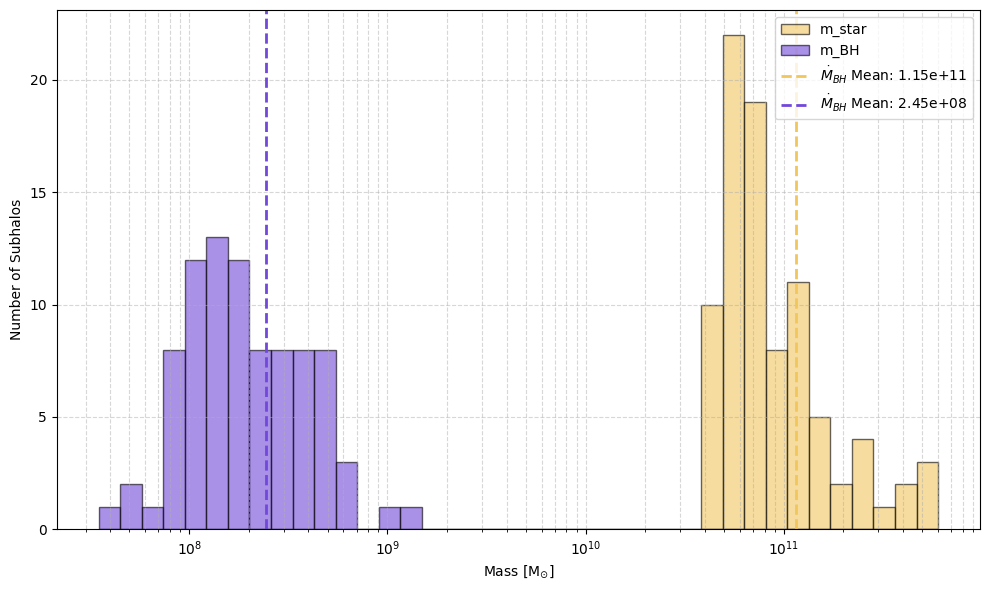

In [21]:
min_mass = min(clean_mstar.min(), clean_mbh.min())
max_mass = max(clean_mstar.max(), clean_mbh.max())
bins_overlap = np.logspace(np.log10(min_mass), np.log10(max_mass), 40)

plt.figure(figsize=(10, 6))
plt.hist(clean_mstar, bins=bins_overlap, color='#f0c65d', alpha=0.6, edgecolor='black', label='m_star')
plt.hist(clean_mbh, bins=bins_overlap, color='#7148d9', alpha=0.6, edgecolor='black', label='m_BH')

plt.axvline(np.mean(clean_mstar), color='#f0c65d', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_mstar):.2e}")
plt.axvline(np.mean(clean_mbh), color='#7148d9', linestyle='--', linewidth=2, label=f"$\dot{{M}}_{{BH}}$ Mean: {np.mean(clean_mbh):.2e}")

plt.xscale('log')
plt.xlabel('Mass [$\mathrm{M}_{\odot}$]')
plt.ylabel('Number of Subhalos')
plt.legend(loc='upper right')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("masses_overlapping.png", dpi=300)
plt.show()

<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_3145/2766174404.py:6: SyntaxWarning: invalid escape sequence '\d'
  plt.ylabel('$\dot{M}_{BH}$/m_BH')


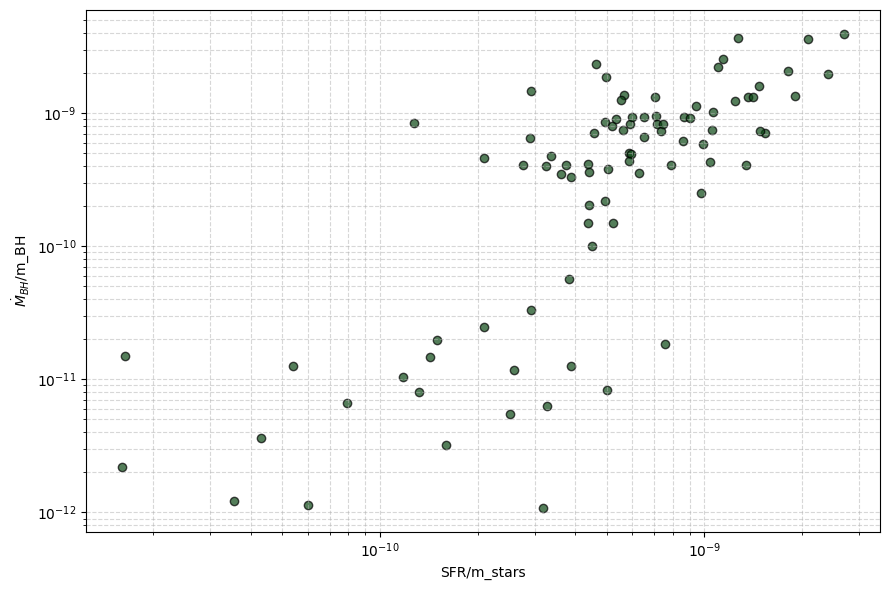

In [22]:
plt.figure(figsize=(9, 6))
plt.scatter(clean_norm_sfrs, clean_norm_bhmdots, color='#0b4714', alpha=0.7, edgecolors='k')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('SFR/m_stars')
plt.ylabel('$\dot{M}_{BH}$/m_BH')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("normalized_sfr_vs_bhmdot_scatter.png", dpi=300)
plt.show()

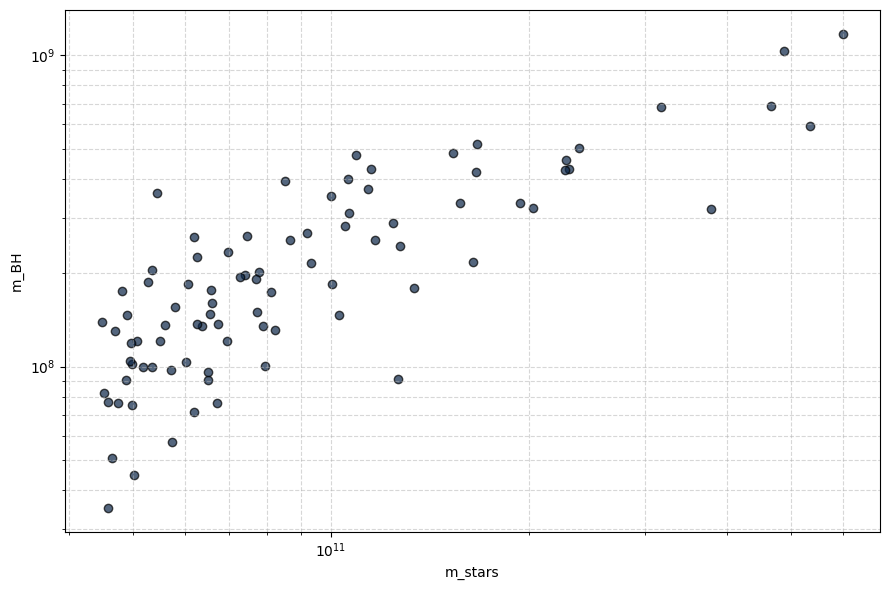

In [23]:
plt.figure(figsize=(9, 6))
plt.scatter(clean_mstar, clean_mbh, color='#0b2547', alpha=0.7, edgecolors='k')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('m_stars')
plt.ylabel('m_BH')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.savefig("mstar_vs_mbh_scatter.png", dpi=300)
plt.show()